In [3]:
# load the data
import pandas as pd
df = pd.read_csv("/content/archive (7).zip")
print(df)

       age          job  marital  education default  balance housing loan  \
0       59       admin.  married  secondary      no     2343     yes   no   
1       56       admin.  married  secondary      no       45      no   no   
2       41   technician  married  secondary      no     1270     yes   no   
3       55     services  married  secondary      no     2476     yes   no   
4       54       admin.  married   tertiary      no      184      no   no   
...    ...          ...      ...        ...     ...      ...     ...  ...   
11157   33  blue-collar   single    primary      no        1     yes   no   
11158   39     services  married  secondary      no      733      no   no   
11159   32   technician   single  secondary      no       29      no   no   
11160   43   technician  married  secondary      no        0      no  yes   
11161   34   technician  married  secondary      no        0      no   no   

        contact  day month  duration  campaign  pdays  previous poutcome  \

   age         job  marital  education default  balance housing loan  contact  \
0   59      admin.  married  secondary      no     2343     yes   no  unknown   
1   56      admin.  married  secondary      no       45      no   no  unknown   
2   41  technician  married  secondary      no     1270     yes   no  unknown   

   day month  duration  campaign  pdays  previous poutcome deposit  
0    5   may      1042         1     -1         0  unknown     yes  
1    5   may      1467         1     -1         0  unknown     yes  
2    5   may      1389         1     -1         0  unknown     yes  
Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'deposit'],
      dtype='object')
<bound method DataFrame.info of        age          job  marital  education default  balance housing loan  \
0       59       admin.  married  secondary      no     2343     yes   n

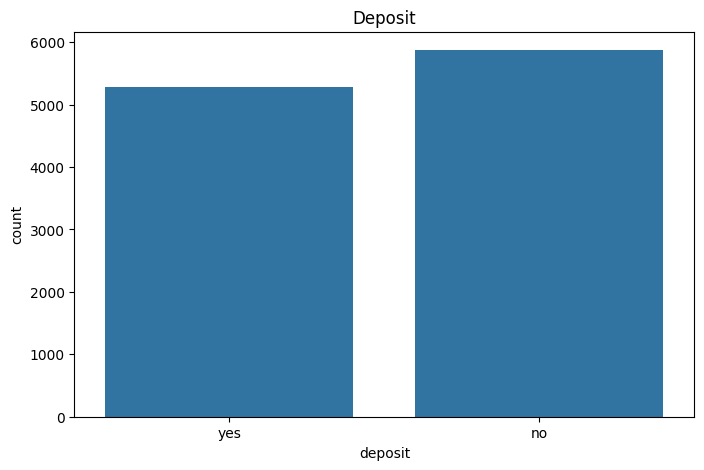

In [4]:
#understand the data
print(df.head(3))
print(df.columns)
print(df.info)
print(df.describe)
print(df.dtypes)
print(df.isnull().sum())
print(df.duplicated().sum())
print(df["deposit"].value_counts())
print(df["deposit"].value_counts(normalize=True)*100)
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,5))
sns.countplot(data=df,x="deposit")
plt.title("Deposit")
plt.show()

Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='object')
                age       balance           day      duration      campaign  \
count  11162.000000  11162.000000  11162.000000  11162.000000  11162.000000   
mean      41.231948   1528.538524     15.658036    371.993818      2.508421   
std       11.913369   3225.413326      8.420740    347.128386      2.722077   
min       18.000000  -6847.000000      1.000000      2.000000      1.000000   
25%       32.000000    122.000000      8.000000    138.000000      1.000000   
50%       39.000000    550.000000     15.000000    255.000000      2.000000   
75%       49.000000   1708.000000     22.000000    496.000000      3.000000   
max       95.000000  81204.000000     31.000000   3881.000000     63.000000   

              pdays      previous  
count  11162.000000  11162.000000  
mean      51.330407      0.832557  
std      108.758282      2.292007  
min       -1.000000      0.000000  
25%       -1.0

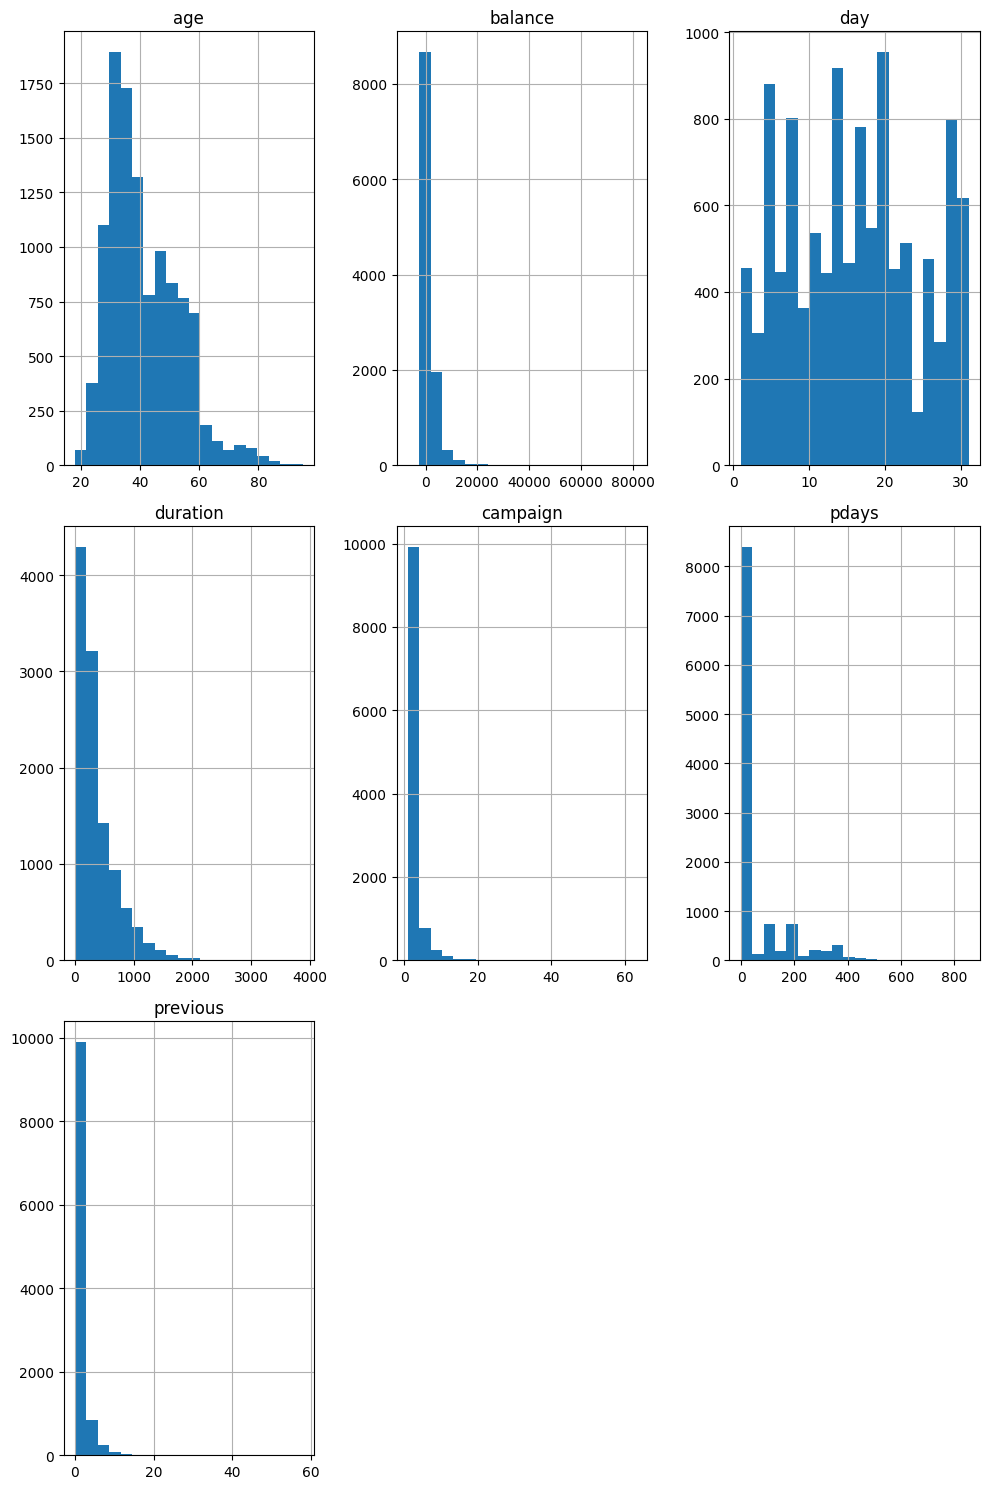

In [5]:
#EDA
num_cols = df.select_dtypes(include="number").columns
print(num_cols)
print(df[num_cols].describe())
df[num_cols].hist(figsize=(10,15),bins=20)
plt.tight_layout()
plt.show()


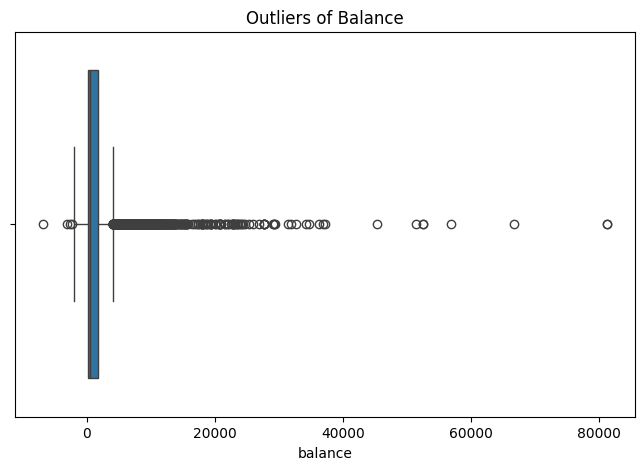

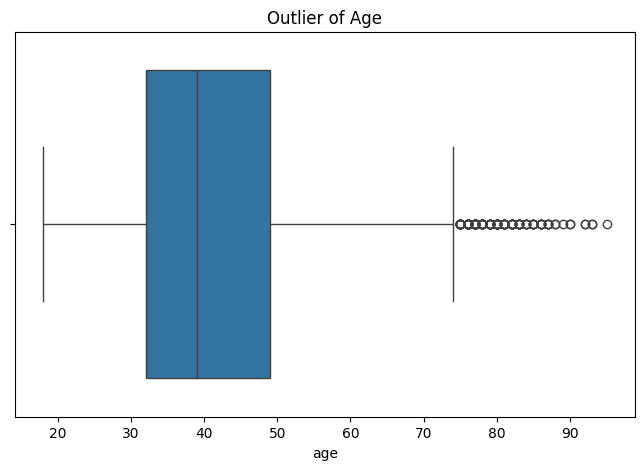

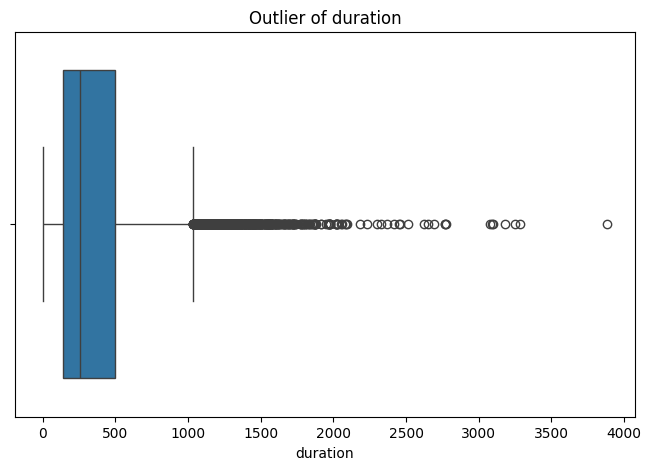

Q1: 122.0
Q3: 1708.0
IQR: 1586.0
upper_limit: 4087.0
Lower_limit: -2257.0
outliers:        age          job   marital  education default  balance housing loan  \
9       28     services    single  secondary      no     5090     yes   no   
60      51  blue-collar   married  secondary      no     7180     yes   no   
61      41  blue-collar  divorced  secondary      no     5291     yes   no   
69      44   technician   married   tertiary      no     4580     yes   no   
71      29   management   married   tertiary      no    10576      no   no   
...    ...          ...       ...        ...     ...      ...     ...  ...   
11073   34  blue-collar   married    primary      no     6718      no   no   
11077   54      retired  divorced   tertiary      no     6102     yes  yes   
11085   60   technician   married    primary      no     4243     yes   no   
11086   42       admin.   married  secondary      no     6445     yes   no   
11101   54  blue-collar   married    primary      no     6

In [6]:
# CHECK OUTLIERS
#Balance outliers
plt.figure(figsize=(8,5))
sns.boxplot(x=df["balance"])
plt.title("Outliers of Balance")
plt.show()


#Age outliers
plt.figure(figsize=(8,5))
sns.boxplot(x=df["age"])
plt.title("Outlier of Age")
plt.show()

#Duration outliers
plt.figure(figsize=(8,5))
sns.boxplot(x=df["duration"])
plt.title("Outlier of duration")
plt.show()
#OUTLIERS DETECTED WITH IQR
#outlier of balance
q1 = df["balance"].quantile(0.25)
q3 = df["balance"].quantile(0.75)
iqr = q3-q1
lower_limit = q1-1.5*iqr
upper_limit = q3+1.5*iqr
print("Q1:",q1)
print("Q3:",q3)
print("IQR:",iqr)
print("upper_limit:",upper_limit)
print("Lower_limit:",lower_limit)
outliers = df[(df["balance"]<lower_limit)|(df["balance"]>upper_limit)]
print("outliers:",outliers)
print("outliers_balance:",outliers["balance"])
print("Total_outliers:",len(outliers))

#Outliers of age
q1=df["age"].quantile(0.25)
q3 =df["age"].quantile(0.75)
iqr = q3-q1
lower_limit = q1-1.5*iqr
upper_limit = q3+1.5*iqr
print("q1:",q1)
print("q3:",q3)
print("iqr:",iqr)
print("lower_limit:",lower_limit)
print("upper_limit:",upper_limit)

outliers_age = df[(df["age"]<lower_limit)|(df["age"]>upper_limit)]
print("outliers_age:",outliers["age"])
print("Total_outliers:",len(outliers_age))


#outliers of duration
q1 = df["duration"].quantile(0.25)
q3 = df["duration"].quantile(0.75)
iqr = q3-q1
lower_limit = q1-1.5*iqr
upper_limit = q3+1.5*iqr

outliers = df[(df["duration"]<lower_limit)|(df["duration"]>upper_limit)]
print("outliers_of_duration",outliers["duration"])
print("Total_outliers:",len(outliers))


In [7]:
# EDA for categorical_columns
cat_cols = df.select_dtypes(include="object").columns
print(cat_cols)
for col in cat_cols:
  print(df[col].value_counts())
  print(col,":",df[col].nunique())

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'deposit'],
      dtype='object')
job
management       2566
blue-collar      1944
technician       1823
admin.           1334
services          923
retired           778
self-employed     405
student           360
unemployed        357
entrepreneur      328
housemaid         274
unknown            70
Name: count, dtype: int64
job : 12
marital
married     6351
single      3518
divorced    1293
Name: count, dtype: int64
marital : 3
education
secondary    5476
tertiary     3689
primary      1500
unknown       497
Name: count, dtype: int64
education : 4
default
no     10994
yes      168
Name: count, dtype: int64
default : 2
housing
no     5881
yes    5281
Name: count, dtype: int64
housing : 2
loan
no     9702
yes    1460
Name: count, dtype: int64
loan : 2
contact
cellular     8042
unknown      2346
telephone     774
Name: count, dtype: int64
contact : 3
month
may    2824
aug    1519
j

In [8]:
cat_columns = df.select_dtypes(include="object").columns

for col in cat_columns:
  mode_value = df[df[col]!="unknown"][col].mode()[0]
  df[col] = df[col].replace("unknown",mode_value)
  print(col,":",(df[col] =="unknown").sum())

job : 0
marital : 0
education : 0
default : 0
housing : 0
loan : 0
contact : 0
month : 0
poutcome : 0
deposit : 0


In [9]:
num_columns = df.select_dtypes(include="number").columns

for col in num_columns:
  df[col]=df[col].fillna(df[col].mean())
print(df[num_columns].isnull().sum())
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())

age         0
balance     0
day         0
duration    0
campaign    0
pdays       0
previous    0
dtype: int64
Total missing values: 0
Total duplicate rows: 0


In [10]:
#Encoding Dataset
cat_columns = df.select_dtypes(include="object").columns
print(cat_columns)

df = pd.get_dummies(df,columns=cat_columns,drop_first=True,dtype=int)
print(df.head(2))
print(df.shape)

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'deposit'],
      dtype='object')
   age  balance  day  duration  campaign  pdays  previous  job_blue-collar  \
0   59     2343    5      1042         1     -1         0                0   
1   56       45    5      1467         1     -1         0                0   

   job_entrepreneur  job_housemaid  ...  month_jul  month_jun  month_mar  \
0                 0              0  ...          0          0          0   
1                 0              0  ...          0          0          0   

   month_may  month_nov  month_oct  month_sep  poutcome_other  \
0          1          0          0          0               0   
1          1          0          0          0               0   

   poutcome_success  deposit_yes  
0                 0            1  
1                 0            1  

[2 rows x 39 columns]
(11162, 39)


In [14]:
# seperate features and Targets
print(df.columns.tolist())
x = df.drop(["deposit_yes","duration"],axis=1)
y = df["deposit_yes"]
print("Feature shape:",x.shape)
print("Target shape:",y.shape)


['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'marital_married', 'marital_single', 'education_secondary', 'education_tertiary', 'default_yes', 'housing_yes', 'loan_yes', 'contact_telephone', 'month_aug', 'month_dec', 'month_feb', 'month_jan', 'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'month_oct', 'month_sep', 'poutcome_other', 'poutcome_success', 'deposit_yes']
Feature shape: (11162, 37)
Target shape: (11162,)


In [15]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test= train_test_split(x,y,
                                                test_size=0.2,
                                                random_state=42,
                                                stratify=y
                                                )

print("x_train:",x_train.shape)
print("x_test:",x_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)


x_train: (8929, 37)
x_test: (2233, 37)
y_train: (8929,)
y_test: (2233,)


In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.fit_transform(x_test)

print("Training_data_Shape:",x_train_scaled)
print("Testing_data_Shape:",x_test_scaled)

Training_data_Shape: [[ 0.41205057 -0.32143142  1.81720843 ... -0.16690632 -0.22520616
  -0.3270968 ]
 [ 0.41205057  0.35953846 -1.50481988 ...  5.991385   -0.22520616
   3.05719901]
 [-1.35630955 -0.45150809 -0.55566894 ... -0.16690632 -0.22520616
   3.05719901]
 ...
 [ 1.16991919  2.29287446 -1.74210762 ... -0.16690632 -0.22520616
  -0.3270968 ]
 [ 1.00150394 -0.34395115 -1.26753215 ... -0.16690632 -0.22520616
  -0.3270968 ]
 [-0.00898755 -0.36613477 -0.67431281 ... -0.16690632 -0.22520616
  -0.3270968 ]]
Testing_data_Shape: [[-0.80780038 -0.32446088  1.48376668 ... -0.18898224 -0.22323855
  -0.32049345]
 [-0.4758042  -0.32863834 -0.30479506 ... -0.18898224 -0.22323855
  -0.32049345]
 [ 0.85218052 -0.24361475  1.24529178 ... -0.18898224 -0.22323855
  -0.32049345]
 ...
 [-0.55880325  0.11982424 -0.4240325  ... -0.18898224 -0.22323855
  -0.32049345]
 [ 0.60318339 -0.40014662 -0.18555761 ... -0.18898224  4.47951311
  -0.32049345]
 [ 1.3501748   0.05740807  1.24529178 ... -0.18898224 -0.

In [17]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(x_train_scaled,y_train)
print("Model Training Completed!")

Model Training Completed!


In [19]:
y_pred = model.predict(x_test_scaled)
print("predicted_values:",y_pred[:20])

predicted_values: [0 1 1 0 0 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1]


In [21]:
from sklearn.metrics import accuracy_score,confusion_matrix
accuracy = accuracy_score(y_test,y_pred)
print("Model_accuracy:",accuracy)
print("Accuracy_percentage:",accuracy*100)
confusion_matrix = confusion_matrix(y_test,y_pred)
print("confusion_matrix:",confusion_matrix)

Model_accuracy: 0.6865203761755486
Accuracy_percentage: 68.65203761755487
confusion_matrix: [[960 215]
 [485 573]]


In [22]:
#Classification Report
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.66      0.82      0.73      1175
           1       0.73      0.54      0.62      1058

    accuracy                           0.69      2233
   macro avg       0.70      0.68      0.68      2233
weighted avg       0.69      0.69      0.68      2233



In [26]:
#Improve Model
from sklearn.linear_model import LogisticRegression

model2 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)
model2.fit(x_train_scaled,y_train)
y_pred2 = model2.predict(x_test_scaled)

In [28]:
# NOW EVALUATE
from sklearn.metrics import accuracy_score,classification_report
print("Accuracy:",accuracy_score(y_test,y_pred2))
print("Classification_report:",classification_report(y_test,y_pred2))

Accuracy: 0.6936856247201075
Classification_report:               precision    recall  f1-score   support

           0       0.68      0.79      0.73      1175
           1       0.71      0.59      0.65      1058

    accuracy                           0.69      2233
   macro avg       0.70      0.69      0.69      2233
weighted avg       0.70      0.69      0.69      2233



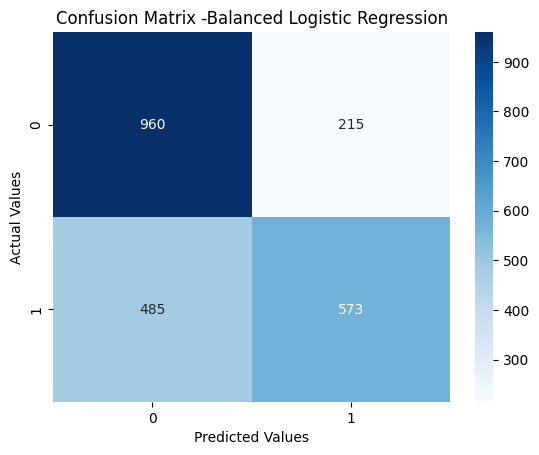

In [30]:
#Visualise Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm2= confusion_matrix(y_test,y_pred)

sns.heatmap(cm2,annot=True,fmt="d",cmap="Blues")

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix -Balanced Logistic Regression")

plt.show()

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

final_model = Pipeline([
    ("scalar",StandardScaler()),
    ("model",LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])
final_model.fit(x_train,y_train)
print("Final Model Training Completed!")

Final Model Training Completed!


In [38]:
#FINAL MODEL EVALUATION
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
final_predictions = final_model.predict(x_test)
#Accuracy
print("Final model Accuracy:",accuracy_score(y_test,final_predictions))

#Classification Report
print("Classification_report:",classification_report(y_test,final_predictions))

#Confusion Matrix
print("Confusion Matrix:",confusion_matrix(y_test,final_predictions))


Final model Accuracy: 0.6914464845499328
Classification_report:               precision    recall  f1-score   support

           0       0.68      0.79      0.73      1175
           1       0.71      0.59      0.64      1058

    accuracy                           0.69      2233
   macro avg       0.70      0.69      0.69      2233
weighted avg       0.69      0.69      0.69      2233

Confusion Matrix: [[923 252]
 [437 621]]


In [39]:
import joblib

joblib.dump(final_model, "bank_marketing_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [40]:
loaded_model = joblib.load("bank_marketing_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!
